# Classificação de Doenças Foliares do Feijoeiro com CNNs

**Autores:** Ana Clara Lima Moreira, Nayara Costa Santos e Rayson Teodoro do Carmo

| Parte | Seção | O que faz |
|---|---|---|
| **Preparação** | 1. Configuração | Bibliotecas, parâmetros, semente e pastas de saída |
| **Dataset** | 2. Organização do dataset | Download, análise, divisão e pré-processamento |
| **Experimento** | 3. Modelos | Definição das três arquiteturas |
| | 4. Treinamento e validação | Treino dos seis experimentos, sem gráficos |
| | 5. Teste | Avaliação final no conjunto de teste, sem gráficos |
| **Resultados** | 6. Resultados e gráficos | Curvas, matrizes de confusão e resumo |
| | 7. Interpretabilidade | Mapas Grad-CAM |

Execute as células na ordem em que aparecem. A seção 6 lê os arquivos salvos pelas seções 4 e 5, então os gráficos podem ser refeitos sem treinar novamente.

# 1. Configuração

Preparação do ambiente usado em todo o notebook.

## 1.1 Instalação das dependências

In [ ]:
# Instalação do KaggleHub e do Grad-CAM
!pip install -U kagglehub
!pip install grad-cam

## 1.2 Bibliotecas

In [ ]:
# Bibliotecas auxiliares para vizualização de graficos, manipulação de arquivos, numerica e afins

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Solicitadas
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,

    classification_report
)
from sklearn.metrics import ConfusionMatrixDisplay

from pathlib import Path
from PIL import Image

## 1.3 Dispositivo

In [ ]:
# Configuração do dispositivo - Ativação da Gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Dispositivo utilizado: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Dispositivo utilizado: cuda
GPU: Tesla T4


## 1.4 Hiperparâmetros

In [ ]:
import argparse

parser = argparse.ArgumentParser(
    description="Bean Leaf Lesions Classification")

parser.add_argument("--epochs", type=int, default=60)
parser.add_argument("--batch_size", type=int, default=16)
parser.add_argument("--lr", type=float, default=1e-4)
parser.add_argument("--weight_decay", type=float, default=1e-4)
parser.add_argument("--optimizer", type=str, default="adam")
parser.add_argument("--loss", type=str, default="ce")
parser.add_argument("--scheduler", type=str, default="plateau")
parser.add_argument("--scheduler_patience", type=int, default=5)
parser.add_argument("--scheduler_factor", type=float, default=0.5)
parser.add_argument("--early_stopping", type=int, default=21)
parser.add_argument("--in_channels", type=int, default=3)
parser.add_argument("--num_classes", type=int, default=3)
parser.add_argument("--height", type=int, default=224)
parser.add_argument("--width", type=int, default=224)
parser.add_argument(
    "--pretrained",
    action=argparse.BooleanOptionalAction,
    default=True
)


# Configuração para o Colab
args = parser.parse_args(args=[])

print(vars(args))

{'epochs': 60, 'batch_size': 16, 'lr': 0.0001, 'weight_decay': 0.0001, 'optimizer': 'adam', 'loss': 'ce', 'scheduler': 'plateau', 'scheduler_patience': 5, 'scheduler_factor': 0.5, 'early_stopping': 21, 'in_channels': 3, 'num_classes': 3, 'height': 224, 'width': 224, 'pretrained': True}


## 1.5 Semente para reprodutibilidade

In [ ]:
# Configuração da semente para reprodutibilidade
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

## 1.6 Pastas de saída

Os pesos, históricos e métricas são salvos no Google Drive.

In [ ]:
# CONEXÃO COM O GOOGLE DRIVE

from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Diretórios

RESULTS_DIR = os.path.join(
    "/content/drive/MyDrive",
    "SIN393_Bean_Leaf_Classification"
)

CHECKPOINT_DIR = os.path.join(RESULTS_DIR, "checkpoints")
HISTORY_DIR = os.path.join(RESULTS_DIR, "history")
METRICS_DIR = os.path.join(RESULTS_DIR, "metrics")

for directory in [CHECKPOINT_DIR, HISTORY_DIR, METRICS_DIR]:
    os.makedirs(directory, exist_ok=True)

print("Diretório principal:", RESULTS_DIR)
print("Pastas criadas com sucesso!")

Diretório principal: /content/drive/MyDrive/SIN393_Bean_Leaf_Classification
Pastas criadas com sucesso!


# 2. Organização do dataset

Tudo o que envolve os dados, antes de qualquer treinamento.

## 2.1 Download

In [ ]:
# Download do dataset
import kagglehub

path = kagglehub.dataset_download(
    "marquis03/bean-leaf-lesions-classification"
)

print("Path to dataset files:", path)

100%|██████████| 155M/155M [00:01<00:00, 102MB/s] 

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/marquis03/bean-leaf-lesions-classification/versions/1


## 2.2 Estrutura dos arquivos

In [ ]:
# Análise da estrutura do dataset


print("=== ESTRUTURA DO DATASET ===")

for root, dirs, files in os.walk(path):
    nivel = os.path.relpath(root, path).count(os.sep)

    if root == path:
        nivel = 0
    else:
        nivel += 1

    indentacao = "    " * nivel

    print(f"{indentacao}{os.path.basename(root)}/")
    print(f"{indentacao}    Total de arquivos: {len(files)}")

    # Mostrar alguns exemplos dos arquivos
    for arquivo in sorted(files)[:5]:
        print(f"{indentacao}    - {arquivo}")

    if len(files) > 5:
        print(f"{indentacao}    ...")

print("\n=== TOTAL DE IMAGENS ===")

extensoes = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for pasta in ["train", "val"]:
    caminho = os.path.join(path, pasta)

    quantidade = sum(
        1
        for root, dirs, files in os.walk(caminho)
        for arquivo in files
        if arquivo.lower().endswith(extensoes)
    )

    print(f"{pasta}: {quantidade} imagens")

print("\n=== ARQUIVO DE CLASSES ===")

with open(os.path.join(path, "classname.txt"), "r") as f:
    print(f.read())

print("\n=== ARQUIVOS CSV ===")

for arquivo in ["train.csv", "val.csv"]:
    df = pd.read_csv(os.path.join(path, arquivo))

    print(f"\n{arquivo}")
    print(f"Dimensões: {df.shape}")
    print("Colunas:", df.columns.tolist())
    print(df.head())

=== ESTRUTURA DO DATASET ===
1/
    Total de arquivos: 3
    - classname.txt
    - train.csv
    - val.csv
    train/
        Total de arquivos: 0
        healthy/
            Total de arquivos: 342
            - healthy_train.0.jpg
            - healthy_train.1.jpg
            - healthy_train.10.jpg
            - healthy_train.100.jpg
            - healthy_train.101.jpg
            ...
        bean_rust/
            Total de arquivos: 348
            - bean_rust_train.0.jpg
            - bean_rust_train.1.jpg
            - bean_rust_train.10.jpg
            - bean_rust_train.100.jpg
            - bean_rust_train.101.jpg
            ...
        angular_leaf_spot/
            Total de arquivos: 345
            - angular_leaf_spot_train.0.jpg
            - angular_leaf_spot_train.1.jpg
            - angular_leaf_spot_train.10.jpg
            - angular_leaf_spot_train.100.jpg
            - angular_leaf_spot_train.101.jpg
            ...
    val/
        Total de arquivos: 0
        health

## 2.3 Divisão em treino, validação e teste

A validação original é mantida. O teste (133 imagens) é separado do treino de forma estratificada.

In [ ]:
## DIVISÃO train_test_split da biblioteca scikit-learn, divisão estratificada
df_train = pd.read_csv(os.path.join(path, "train.csv"))
df_val = pd.read_csv(os.path.join(path, "val.csv"))

train_df, test_df = train_test_split(
    df_train,
    test_size=133,
    stratify=df_train["category"], # ---> category para rotulo de cada classe
    random_state=SEED
)

# Verificação da divisão
print(f"Train: {len(train_df)} images")
print(f"Test: {len(test_df)} images")
print(f"Validation: {len(df_val)} imagns")

Train: 901 images
Test: 133 images
Validation: 133 imagns


## 2.4 Distribuição das classes

In [ ]:
# DISTRIBUIÇÃO DE CLASSES
distribution = pd.DataFrame({
    "Train": train_df["category"].value_counts(),
    "Test": test_df["category"].value_counts(),
    "Validation": df_val["category"].value_counts()
}).fillna(0).astype(int).sort_index()

# Identificação das classes - 3
distribution.index = [
    "Healthy",
    "Angular Leaf Spot",
    "Bean Rust"
]

print("Distribuição das imagens por classe:")
display(distribution)

Distribuição das imagens por classe:


,Train,Test,Validation
Healthy,297,44,44
Angular Leaf Spot,301,44,44
Bean Rust,303,45,45


## 2.5 Pré-processamento e data augmentation

O data augmentation é aplicado somente ao treino.

In [ ]:
# Pré-processamento
def get_transforms(model_name, height, width, da_train="none"):

    # Seleção dos pesos para normalização
    if model_name == "resnet18":
        weights = models.ResNet18_Weights.DEFAULT

    elif model_name == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.DEFAULT

    elif model_name == "simple_cnn":
        weights = models.ResNet18_Weights.DEFAULT

    else:
        raise ValueError(f"Arquitetura desconhecida: {model_name}")

    preprocess = weights.transforms()

    # Redimensionamento
    transform_list = [
        transforms.Resize((height, width))
    ]


  # Data Augmentation moderado
    if da_train == "moderate":
        transform_list.extend([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.5),

            # Preenchimento por reflexão antes da rotação
            transforms.Pad(
                padding=44,
                padding_mode="reflect"
            ),
            transforms.RandomRotation(degrees=20),
            transforms.CenterCrop((height, width)),

            # Variação de brilho
            transforms.RandomApply([
                transforms.ColorJitter(brightness=0.15)
            ], p=0.5)
        ])


    elif da_train != "none":
        raise ValueError(f"Data Augmentation desconhecido: {da_train}")

    # Conversão para tensor e normalização
    transform_list.extend([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=preprocess.mean,
            std=preprocess.std
        )
    ])

    return transforms.Compose(transform_list)

## 2.6 Dataset e DataLoaders

In [ ]:
# Classe do Dataset
class BeanLeafDataset(Dataset):

  def __init__(self, dataframe, root_dir, transform=None):
    self.dataframe = dataframe.reset_index(drop=True)
    self.root_dir = root_dir
    self.transform = transform

  def __len__(self):
        return len(self.dataframe)

  def __getitem__(self, idx):

        image_path = os.path.join(
            self.root_dir,
            self.dataframe.iloc[idx]["image:FILE"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        label = int(self.dataframe.iloc[idx]["category"])

        if self.transform is not None:
            image = self.transform(image)

        return image, label

In [ ]:
#Data Loaders

def get_datasets(model_name, height, width, da_train="none"):

    # Transformações para treinamento
    train_transform = get_transforms(
        model_name, height, width, da_train
    )

    # Transformações para validação e teste
    eval_transform = get_transforms(
        model_name, height, width, "none"
    )

    # Dataset de treinamento
    train_dataset = BeanLeafDataset(
        dataframe=train_df,
        root_dir=path,
        transform=train_transform
    )

    # Dataset de validação
    val_dataset = BeanLeafDataset(
        dataframe=df_val,
        root_dir=path,
        transform=eval_transform
    )

    # Dataset de teste
    test_dataset = BeanLeafDataset(
        dataframe=test_df,
        root_dir=path,
        transform=eval_transform
    )

    return train_dataset, val_dataset, test_dataset

In [ ]:
# Data Loaders

def get_dataloaders(model_name, height, width, batch_size, da_train="none"):

    # Criação dos Datasets
    train_dataset, val_dataset, test_dataset = get_datasets(
        model_name, height, width, da_train
    )

    # Treinamento
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    # Validação
    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    # Teste
    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, val_loader, test_loader

## 2.7 Amostras com data augmentation

Conferência visual das transformações em cada classe.

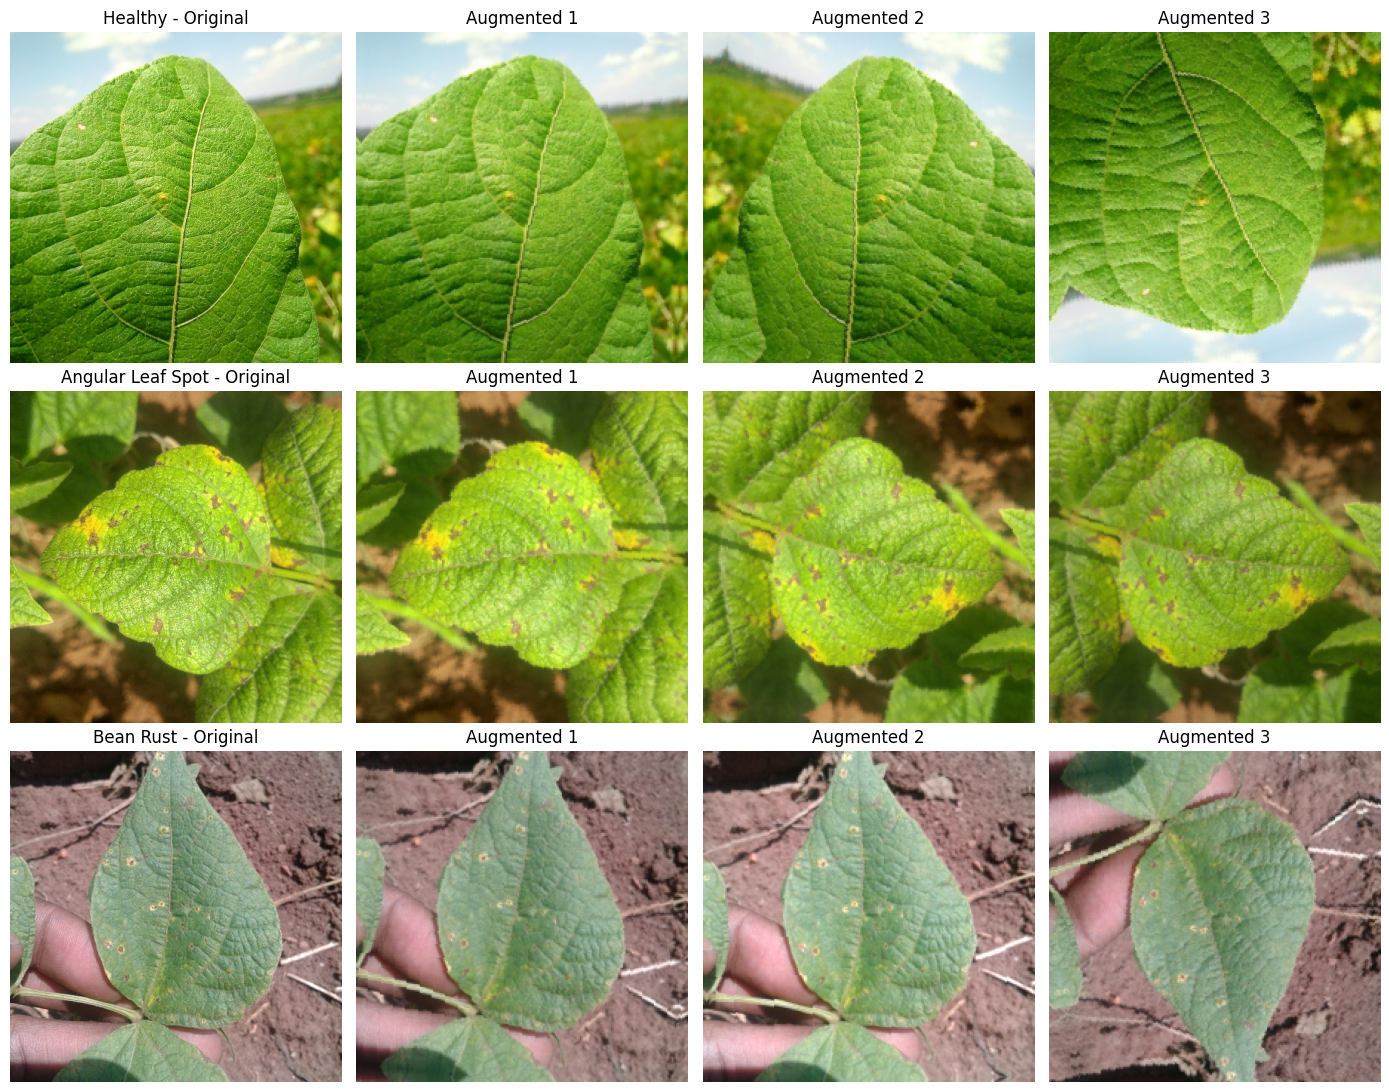

In [ ]:
# VISUALIZAÇÃO DO DATA AUGMENTATION POR CLASSE

# Transformações com Data Augmentation
transform = get_transforms(
    model_name="resnet18",
    height=args.height,
    width=args.width,
    da_train="moderate"
)

# Normalização inversa para visualização
preprocess = models.ResNet18_Weights.DEFAULT.transforms()

mean = torch.tensor(preprocess.mean).view(3, 1, 1)
std = torch.tensor(preprocess.std).view(3, 1, 1)

# Classes do dataset
class_names = [
    "Healthy",
    "Angular Leaf Spot",
    "Bean Rust"
]

# Uma linha para cada classe e quatro colunas
fig, axes = plt.subplots(3, 4, figsize=(14, 11))

for class_id, class_name in enumerate(class_names):

    # Seleção de uma imagem da classe
    sample = train_df[
        train_df["category"] == class_id
    ].iloc[0]

    sample_path = os.path.join(
        path, sample["image:FILE"]
    )

    with Image.open(sample_path) as img:
        image = img.convert("RGB")

    # Imagem original
    axes[class_id, 0].imshow(image)
    axes[class_id, 0].set_title(f"{class_name} - Original")
    axes[class_id, 0].axis("off")

    # Três versões com Data Augmentation
    for i in range(1, 4):
        augmented = transform(image)

        # Desfaz a normalização
        augmented = augmented * std + mean
        augmented = augmented.clamp(0, 1)

        axes[class_id, i].imshow(
            augmented.permute(1, 2, 0)
        )
        axes[class_id, i].set_title(f"Augmented {i}")
        axes[class_id, i].axis("off")

plt.tight_layout()
plt.show()



#regioes artificias menos abruptas pelo pad = refçlect

# 3. Modelos

## 3.1 CNN simples (baseada na LeNet-5)

In [ ]:
# MODELO CNN SIMPLES (LeNet5 adaptada, seguindo o tutorial do pyTorch: https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html).
# 5 camadas: 2 convolucionais (6 e 16 filtros 5x5) + 3 totalmente conectadas (120, 84, 3 neuronios)

# adaptações:
# 3 saídas
# entrada rgb de 500x500 pixels
# ativação ReLu
# maxpooling
# pooling adaptativo para 5x5
# camada linear
# Conexões completas

class Net(nn.Module):
  def __init__(self, n_classes=3):
    super().__init__()
    self.conv1 = nn.Conv2d(3, 6, 5)
    self.pool = nn.MaxPool2d(2, 2)
    self.conv2 = nn.Conv2d(6, 16, 5)
    self.gap = nn.AdaptiveAvgPool2d((5,5))
    self.fc1 = nn.Linear(16 * 5 * 5, 120)
    self.fc2 = nn.Linear(120, 84)
    self.fc3 = nn.Linear(84, n_classes)

  def forward(self, x):
    x = self.pool(F.relu(self.conv1(x)))
    x = self.pool(F.relu(self.conv2(x)))
    x = self.gap(x)
    x = torch.flatten(x, 1)
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    return self.fc3(x)

## 3.2 Seleção da arquitetura

CNN simples, ResNet-18 ou EfficientNet-B0.

In [ ]:
# Definição das arquiteturas

def get_model(model_name, num_classes, pretrained=True):

    if model_name == "simple_cnn":
        model = Net(n_classes=num_classes)

    elif model_name == "resnet18":
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None

        model = models.resnet18(weights=weights)

        # Adaptação da camada de classificação
        model.fc = nn.Linear(
            model.fc.in_features,
            num_classes
        )

    elif model_name == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None

        model = models.efficientnet_b0(weights=weights)

        # Adaptação da camada de classificação
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features,
            num_classes
        )

    else:
        raise ValueError(f"Arquitetura desconhecida: {model_name}")

    return model

# 4. Treinamento e validação

O teste não é usado nesta etapa. A melhor época é escolhida pela perda de validação.

## 4.1 Definição dos experimentos

In [ ]:
# Definições experimentais
# CONFIGURAÇÕES DOS EXPERIMENTOS

model_list_ = ["simple_cnn", "resnet18", "efficientnet_b0"]

da_list_ = ["none", "moderate"]

In [ ]:
# Configuracoes de experimentos

def get_training_config(model, args):

    # Função de perda
    if args.loss == "ce":
        criterion = nn.CrossEntropyLoss()
    else:
        raise ValueError(f"Loss desconhecida: {args.loss}")

    # Otimizador
    if args.optimizer == "adam":
        optimizer = optim.Adam(
            model.parameters(),
            lr=args.lr,
            weight_decay=args.weight_decay
        )
    else:
        raise ValueError(f"Otimizador desconhecido: {args.optimizer}")

    # Scheduler
    if args.scheduler == "plateau":
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=args.scheduler_factor,
            patience=args.scheduler_patience
        )
    elif args.scheduler == "none":
        scheduler = None
    else:
        raise ValueError(f"Scheduler desconhecido: {args.scheduler}")

    return criterion, optimizer, scheduler

## 4.2 Métricas e avaliação

Funções usadas tanto na validação quanto no teste.

In [ ]:
# Cálculo das métricas

def classification_metrics(y_true, y_pred):

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

    return metrics

In [ ]:
# AVALIAÇÃO DOS MODELOS

def evaluate_model(model, data_loader, device):

    model.eval()

    y_true = []
    y_pred = []

    # Predição sem atualização de pesos
    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)

            # Forward
            outputs = model(images)

            # Classes previstas
            predictions = outputs.argmax(dim=1)

            # Armazenamento dos rótulos
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    # Métricas globais (macro)
    metrics = classification_metrics(y_true, y_pred)

    # Métricas por classe
    class_report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=[
            "Healthy",
            "Angular Leaf Spot",
            "Bean Rust"
        ],
        output_dict=True,
        zero_division=0
    )

    # Matriz de confusão
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2]
    )

    return metrics, class_report, cm, y_true, y_pred

In [ ]:
#salvamento de métricas

def save_evaluation(metrics, class_report, cm, model_name, da_train):

    # Identificação do experimento
    experiment_name = f"{model_name}_{da_train}"

    # Métricas macro
    metrics_df = pd.DataFrame([metrics])

    metrics_path = os.path.join(
        METRICS_DIR,
        f"{experiment_name}_metrics.csv"
    )

    metrics_df.to_csv(metrics_path, index=False)

    # Métricas por classe
    class_df = pd.DataFrame(class_report).T

    class_path = os.path.join(
        METRICS_DIR,
        f"{experiment_name}_per_class.csv"
    )

    class_df.to_csv(class_path)

    # Matriz de confusão
    cm_df = pd.DataFrame(
        cm,
        index=["Healthy", "Angular Leaf Spot", "Bean Rust"],
        columns=["Healthy", "Angular Leaf Spot", "Bean Rust"]
    )

    cm_path = os.path.join(
        METRICS_DIR,
        f"{experiment_name}_confusion_matrix.csv"
    )

    cm_df.to_csv(cm_path)

    print(f"Resultados salvos: {experiment_name}")

## 4.3 Funções de treinamento

In [ ]:
# TREINAMENTO - UMA ÉPOCA

def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        # Transferência para o dispositivo
        images = images.to(device)
        labels = labels.to(device)

        # Zerar os gradientes
        optimizer.zero_grad()

        # Forward
        outputs = model(images)

        # Cálculo da loss
        loss = criterion(outputs, labels)

        # Backward
        loss.backward()

        # Atualização dos pesos
        optimizer.step()

        # Acumulação das métricas
        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
# Validação uma época


def validate_one_epoch(model, val_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)

            running_loss += loss.item() * images.size(0)

            y_true.extend(labels.cpu().tolist())
            y_pred.extend(predictions.cpu().tolist())

    epoch_loss = running_loss / len(val_loader.dataset)

    metrics = classification_metrics(y_true, y_pred)

    return epoch_loss, metrics

In [ ]:
# Treino completo


def train_model(model, train_loader, val_loader, args,
                device, model_name, da_train):

    criterion, optimizer, scheduler = get_training_config(model, args)

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "val_precision": [],
        "val_recall": [],
        "val_f1": [],
        "lr": []
    }

    best_val_loss = float("inf")
    best_epoch = 0
    best_model_state = None
    patience_counter = 0

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"{model_name}_{da_train}.pth"
    )

    for epoch in range(args.epochs):

        # Treinamento
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )

        # Validação
        val_loss, val_metrics = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Histórico
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_metrics["accuracy"])
        history["val_precision"].append(val_metrics["precision"])
        history["val_recall"].append(val_metrics["recall"])
        history["val_f1"].append(val_metrics["f1"])
        history["lr"].append(optimizer.param_groups[0]["lr"])

        # Scheduler
        if scheduler is not None:
            scheduler.step(val_loss)

        # Melhor checkpoint
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1
            patience_counter = 0

            best_model_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            torch.save({
                "epoch": best_epoch,
                "model_name": model_name,
                "da_train": da_train,
                "model_state_dict": best_model_state,
                "best_val_loss": best_val_loss,
                "config": vars(args).copy()
            }, checkpoint_path)

        else:
            patience_counter += 1

        # Exibição
        print(
            f"Epoch [{epoch + 1}/{args.epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_metrics['accuracy']:.4f} | "
            f"Precision: {val_metrics['precision']:.4f} | "
            f"Recall: {val_metrics['recall']:.4f} | "
            f"F1: {val_metrics['f1']:.4f}"
        )

        # Early Stopping
        if patience_counter >= args.early_stopping:
            print(f"\nEarly Stopping na época {epoch + 1}")
            break

    # Recupera o melhor modelo
    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    print(f"\nMelhor época: {best_epoch}")
    print(f"Melhor Val Loss: {best_val_loss:.4f}")

    # Salva histórico
    history_df = pd.DataFrame(history)
    history_df.insert(
        0, "epoch", range(1, len(history_df) + 1)
    )

    history_path = os.path.join(
        HISTORY_DIR,
        f"{model_name}_{da_train}.csv"
    )

    history_df.to_csv(history_path, index=False)

    print(f"Histórico salvo em: {history_path}")

    return model, history, best_epoch

In [ ]:
# Executando um experimento


def run_experiment(model_name, da_train, args, device):

    print(f"\n=== Modelo: {model_name} | DA: {da_train} ===")

    # Reprodutibilidade
    random.seed(args.seed)
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(args.seed)

    # DataLoaders
    train_loader, val_loader, test_loader = get_dataloaders(
        model_name=model_name,
        height=args.height,
        width=args.width,
        batch_size=args.batch_size,
        da_train=da_train
    )

    # Modelo
    model = get_model(
        model_name=model_name,
        num_classes=args.num_classes,
        pretrained=args.pretrained
    ).to(device)

    # Treinamento
    model, history, best_epoch = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        args=args,
        device=device,
        model_name=model_name,
        da_train=da_train
    )

    # Avaliação no conjunto de validação
    metrics, class_report, cm, y_true, y_pred = evaluate_model(
        model, val_loader, device
    )

    print("\n=== MÉTRICAS DE VALIDAÇÃO ===")
    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value:.4f}")

    # Salva resultados com identificação do conjunto
    evaluation_name = f"{da_train}_val"

    save_evaluation(
        metrics, class_report, cm,
        model_name, evaluation_name
    )

    print(
        f"\nExperimento concluído: {model_name} | "
        f"DA: {da_train} | Melhor época: {best_epoch}"
    )

    return model, history, val_loader, test_loader

## 4.4 Conferência das configurações

In [ ]:
# VERIFICAÇÃO FINAL DAS CONFIGURAÇÕES

print("=== AMBIENTE ===")
print(f"Dispositivo: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

print("\n=== DATASET ===")
print(f"Treinamento: {len(train_df)} imagens")
print(f"Validação: {len(df_val)} imagens")
print(f"Teste: {len(test_df)} imagens")
print(f"Resolução: {args.height}x{args.width}")
print(f"Classes: {args.num_classes}")

print("\n=== HIPERPARÂMETROS ===")
print(f"Épocas: {args.epochs}")
print(f"Batch size: {args.batch_size}")
print(f"Learning rate: {args.lr}")
print(f"Weight decay: {args.weight_decay}")
print(f"Optimizer: {args.optimizer}")
print(f"Loss: {args.loss}")
print(f"Scheduler: {args.scheduler}")
print(f"Scheduler patience: {args.scheduler_patience}")
print(f"Early Stopping: {args.early_stopping}")
print(f"Pretrained: {args.pretrained}")

print("\n=== EXPERIMENTOS ===")

for model_name in model_list_:
    for da_train in da_list_:
        print(f"{model_name} | DA: {da_train}")

print("\n=== DIRETÓRIOS ===")
for directory in [CHECKPOINT_DIR, HISTORY_DIR, METRICS_DIR]:
    print(f"{directory}: {os.path.isdir(directory)}")

=== AMBIENTE ===
Dispositivo: cuda
GPU: Tesla T4

=== DATASET ===
Treinamento: 901 imagens
Validação: 133 imagens
Teste: 133 imagens
Resolução: 224x224
Classes: 3

=== HIPERPARÂMETROS ===
Épocas: 60
Batch size: 16
Learning rate: 0.0001
Weight decay: 0.0001
Optimizer: adam
Loss: ce
Scheduler: plateau
Scheduler patience: 5
Early Stopping: 21
Pretrained: True

=== EXPERIMENTOS ===
simple_cnn | DA: none
simple_cnn | DA: moderate
resnet18 | DA: none
resnet18 | DA: moderate
efficientnet_b0 | DA: none
efficientnet_b0 | DA: moderate

=== DIRETÓRIOS ===
/content/drive/MyDrive/SIN393_Bean_Leaf_Classification/checkpoints: True
/content/drive/MyDrive/SIN393_Bean_Leaf_Classification/history: True
/content/drive/MyDrive/SIN393_Bean_Leaf_Classification/metrics: True


## 4.5 Execução do treinamento

Experimentos já concluídos são pulados.

In [ ]:
# EXECUÇÃO DE TODOS OS EXPERIMENTOS
args.seed = SEED

for model_name in model_list_:
    for da_train in da_list_:

        experiment_name = f"{model_name}_{da_train}"

        completed_path = os.path.join(
            RESULTS_DIR,
            f"{experiment_name}_completed.txt"
        )

        if os.path.isfile(completed_path):
            print(f"Experimento concluído anteriormente: {experiment_name}")
            continue

        model, history, val_loader, test_loader = run_experiment(
            model_name=model_name,
            da_train=da_train,
            args=args,
            device=device
        )

        # Marca a conclusão somente após todas as etapas
        with open(completed_path, "w") as file:
            file.write("completed")

        # Libera memória
        del model, history, val_loader, test_loader

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print("\nTodos os experimentos foram concluídos!")


=== Modelo: simple_cnn | DA: none ===
Epoch [1/60] | Train Loss: 1.0920 | Train Acc: 0.4273 | Val Loss: 1.0828 | Val Acc: 0.5113 | Precision: 0.6153 | Recall: 0.5077 | F1: 0.4457
Epoch [2/60] | Train Loss: 1.0532 | Train Acc: 0.5938 | Val Loss: 1.0250 | Val Acc: 0.5940 | Precision: 0.6069 | Recall: 0.5928 | F1: 0.5897
Epoch [3/60] | Train Loss: 0.9454 | Train Acc: 0.6337 | Val Loss: 0.9254 | Val Acc: 0.6015 | Precision: 0.6257 | Recall: 0.6005 | F1: 0.5974
Epoch [4/60] | Train Loss: 0.8293 | Train Acc: 0.6737 | Val Loss: 0.8234 | Val Acc: 0.6541 | Precision: 0.6586 | Recall: 0.6539 | F1: 0.6537
Epoch [5/60] | Train Loss: 0.7482 | Train Acc: 0.6992 | Val Loss: 0.7652 | Val Acc: 0.6617 | Precision: 0.6663 | Recall: 0.6611 | F1: 0.6586
Epoch [6/60] | Train Loss: 0.7049 | Train Acc: 0.7037 | Val Loss: 0.7186 | Val Acc: 0.6767 | Precision: 0.6742 | Recall: 0.6768 | F1: 0.6739
Epoch [7/60] | Train Loss: 0.6765 | Train Acc: 0.7314 | Val Loss: 0.7165 | Val Acc: 0.6767 | Precision: 0.6842 | Re

100%|██████████| 44.7M/44.7M [00:00<00:00, 224MB/s]


Epoch [1/60] | Train Loss: 0.4094 | Train Acc: 0.8302 | Val Loss: 0.1443 | Val Acc: 0.9474 | Precision: 0.9475 | Recall: 0.9476 | F1: 0.9473
Epoch [2/60] | Train Loss: 0.0627 | Train Acc: 0.9800 | Val Loss: 0.1239 | Val Acc: 0.9549 | Precision: 0.9585 | Recall: 0.9545 | F1: 0.9551
Epoch [3/60] | Train Loss: 0.0286 | Train Acc: 0.9933 | Val Loss: 0.0915 | Val Acc: 0.9699 | Precision: 0.9728 | Recall: 0.9697 | F1: 0.9699
Epoch [4/60] | Train Loss: 0.0300 | Train Acc: 0.9933 | Val Loss: 0.0591 | Val Acc: 0.9699 | Precision: 0.9700 | Recall: 0.9700 | F1: 0.9700
Epoch [5/60] | Train Loss: 0.0139 | Train Acc: 0.9967 | Val Loss: 0.0702 | Val Acc: 0.9774 | Precision: 0.9778 | Recall: 0.9774 | F1: 0.9775
Epoch [6/60] | Train Loss: 0.0220 | Train Acc: 0.9945 | Val Loss: 0.0704 | Val Acc: 0.9699 | Precision: 0.9728 | Recall: 0.9697 | F1: 0.9699
Epoch [7/60] | Train Loss: 0.0083 | Train Acc: 0.9989 | Val Loss: 0.0535 | Val Acc: 0.9699 | Precision: 0.9712 | Recall: 0.9697 | F1: 0.9699
Epoch [8/60] 

100%|██████████| 20.5M/20.5M [00:00<00:00, 216MB/s]


Epoch [1/60] | Train Loss: 0.8063 | Train Acc: 0.6415 | Val Loss: 0.4628 | Val Acc: 0.8496 | Precision: 0.8490 | Recall: 0.8502 | F1: 0.8477
Epoch [2/60] | Train Loss: 0.3868 | Train Acc: 0.8879 | Val Loss: 0.2411 | Val Acc: 0.9173 | Precision: 0.9174 | Recall: 0.9177 | F1: 0.9170
Epoch [3/60] | Train Loss: 0.1819 | Train Acc: 0.9534 | Val Loss: 0.1540 | Val Acc: 0.9474 | Precision: 0.9488 | Recall: 0.9473 | F1: 0.9470
Epoch [4/60] | Train Loss: 0.1090 | Train Acc: 0.9734 | Val Loss: 0.1417 | Val Acc: 0.9398 | Precision: 0.9395 | Recall: 0.9401 | F1: 0.9396
Epoch [5/60] | Train Loss: 0.0765 | Train Acc: 0.9845 | Val Loss: 0.1096 | Val Acc: 0.9699 | Precision: 0.9699 | Recall: 0.9700 | F1: 0.9699
Epoch [6/60] | Train Loss: 0.0456 | Train Acc: 0.9889 | Val Loss: 0.1249 | Val Acc: 0.9549 | Precision: 0.9549 | Recall: 0.9551 | F1: 0.9547
Epoch [7/60] | Train Loss: 0.0673 | Train Acc: 0.9789 | Val Loss: 0.1523 | Val Acc: 0.9398 | Precision: 0.9397 | Recall: 0.9399 | F1: 0.9397
Epoch [8/60] 

# 5. Teste

Avaliação final dos melhores pesos de cada experimento, em imagens que não participaram do treino nem da escolha da época.

## 5.1 Carregamento do melhor modelo

In [ ]:
# carrega o melhor modelo
def load_best_model(model_name, da_train, args, device):
    checkpoint = torch.load(
        os.path.join(CHECKPOINT_DIR, f"{model_name}_{da_train}.pth"),
        map_location=device,
        weights_only=False
    )
    model = get_model(model_name, args.num_classes, pretrained=False).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    return model, checkpoint["epoch"]

## 5.2 Execução do teste

In [ ]:
# testa os melhores modelos
results = []

for model_name in model_list_:
    for da_train in da_list_:
        experiment_name = f"{model_name}_{da_train}"
        print(f"\n=== Teste: {experiment_name} ===")

        model, best_epoch = load_best_model(model_name, da_train, args, device)
        _, _, test_loader = get_dataloaders(model_name, args.height, args.width, args.batch_size)

        metrics, class_report, cm, y_true, y_pred = evaluate_model(model, test_loader, device)

        for metric_name, value in metrics.items():
            print(f"{metric_name}: {value:.4f}")

        save_evaluation(metrics, class_report, cm, model_name, f"{da_train}_test")

        val_metrics = pd.read_csv(
            os.path.join(METRICS_DIR, f"{experiment_name}_val_metrics.csv")
        ).iloc[0]

        results.append({
            "model": model_name,
            "da": da_train,
            "best_epoch": best_epoch,
            **{f"val_{k}": val_metrics[k] for k in metrics},
            **{f"test_{k}": v for k, v in metrics.items()}
        })

        del model, test_loader
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

summary = (
    pd.DataFrame(results)
    .sort_values("val_f1", ascending=False)
    .reset_index(drop=True)
)

summary.to_csv(os.path.join(RESULTS_DIR, "summary_val_test.csv"), index=False)


=== Teste: simple_cnn_none ===
accuracy: 0.7744
precision: 0.7749
recall: 0.7753
f1: 0.7743
Resultados salvos: simple_cnn_none_test


# 6. Resultados e gráficos

Esta seção não treina nem testa modelos: apenas lê e apresenta o que foi salvo.

## 6.1 Funções de visualização

In [ ]:
# Gráficos

def plot_training_history(history, model_name, da_train):

    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Loss
    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross Entropy Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Accuracy
    axes[1].plot(epochs, history["train_acc"], label="Train")
    axes[1].plot(epochs, history["val_acc"], label="Validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(f"{model_name} - DA: {da_train}")

    plt.tight_layout()

    # Salvamento automático
    figure_path = os.path.join(
        HISTORY_DIR,
        f"{model_name}_{da_train}_curves.png"
    )

    plt.savefig(figure_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Gráficos salvos em: {figure_path}")

In [ ]:
# Matriz de confusão

def plot_confusion_matrix(cm, model_name, da_train):

    class_names = [
        "Healthy",
        "Angular Leaf Spot",
        "Bean Rust"
    ]

    fig, ax = plt.subplots(figsize=(7, 6))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{model_name} - DA: {da_train}")

    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    figure_path = os.path.join(
        METRICS_DIR,
        f"{model_name}_{da_train}_confusion_matrix.png"
    )

    plt.savefig(figure_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def load_confusion_matrix(model_name, evaluation_name):

    cm_path = os.path.join(
        METRICS_DIR,
        f"{model_name}_{evaluation_name}_confusion_matrix.csv"
    )

    return pd.read_csv(cm_path, index_col=0).to_numpy()

## 6.2 Curvas de treinamento

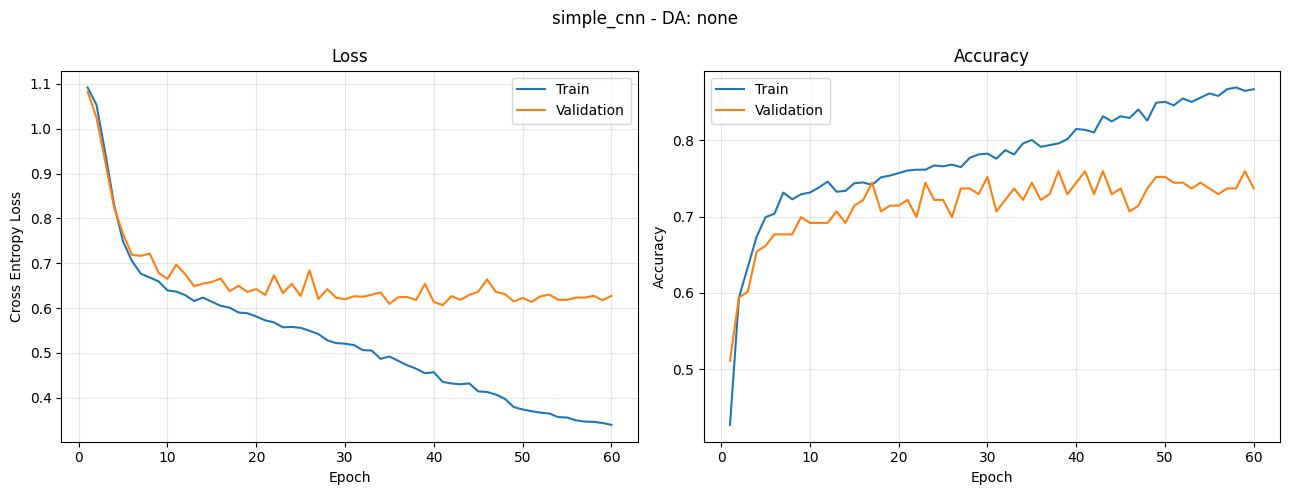

Gráficos salvos em: /content/drive/MyDrive/SIN393_Bean_Leaf_Classification/history/simple_cnn_none_curves.png


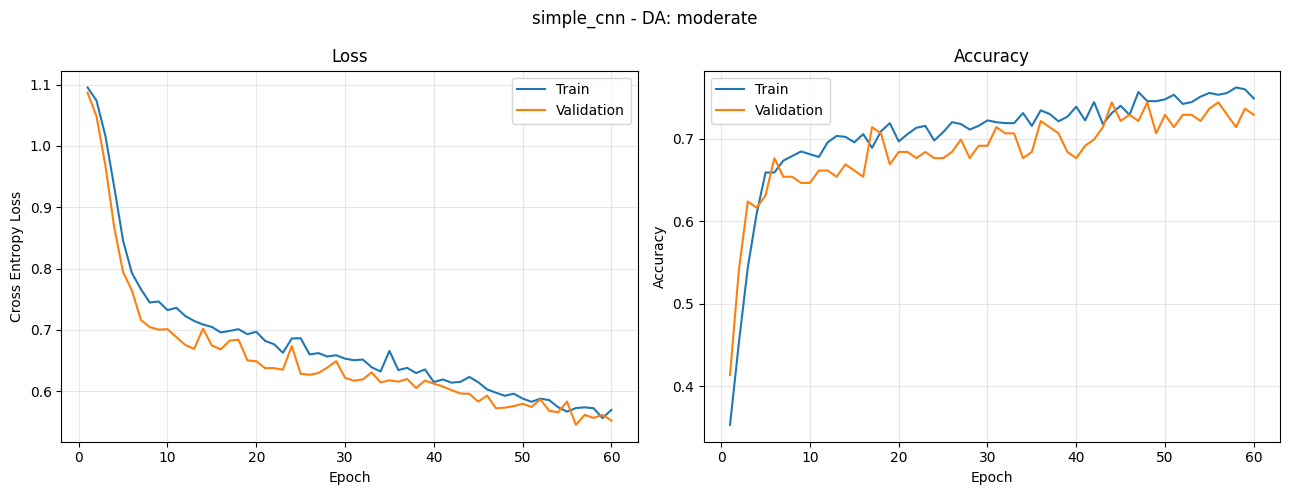

Gráficos salvos em: /content/drive/MyDrive/SIN393_Bean_Leaf_Classification/history/simple_cnn_moderate_curves.png


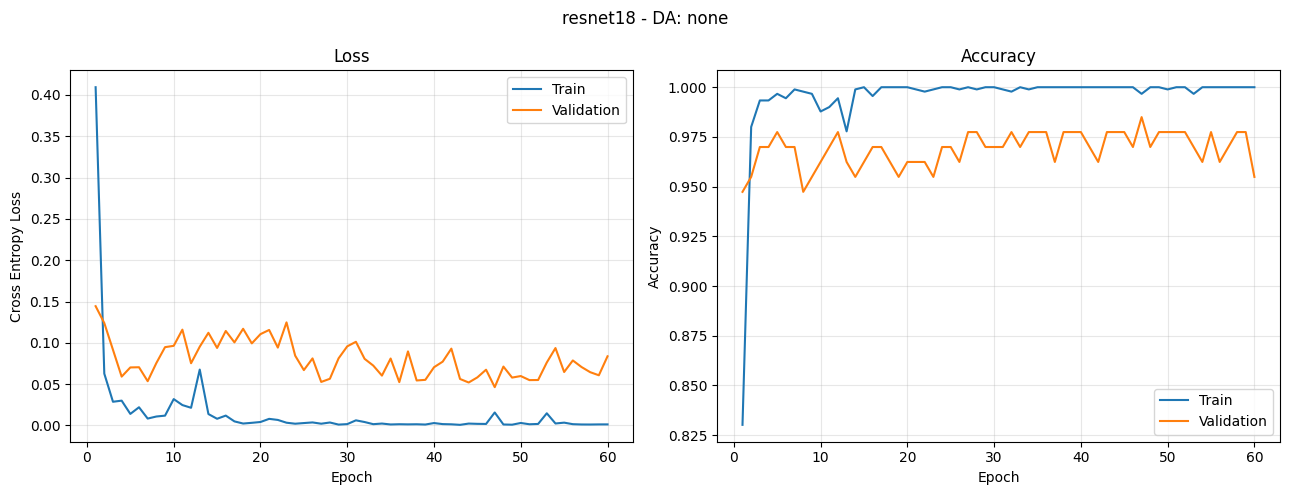

Gráficos salvos em: /content/drive/MyDrive/SIN393_Bean_Leaf_Classification/history/resnet18_none_curves.png


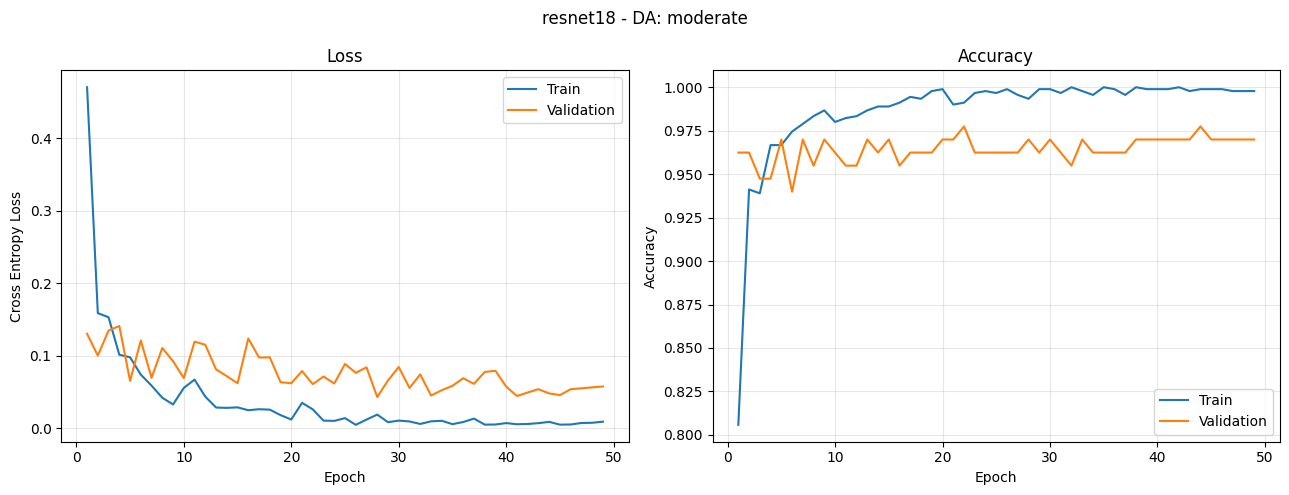

Gráficos salvos em: /content/drive/MyDrive/SIN393_Bean_Leaf_Classification/history/resnet18_moderate_curves.png


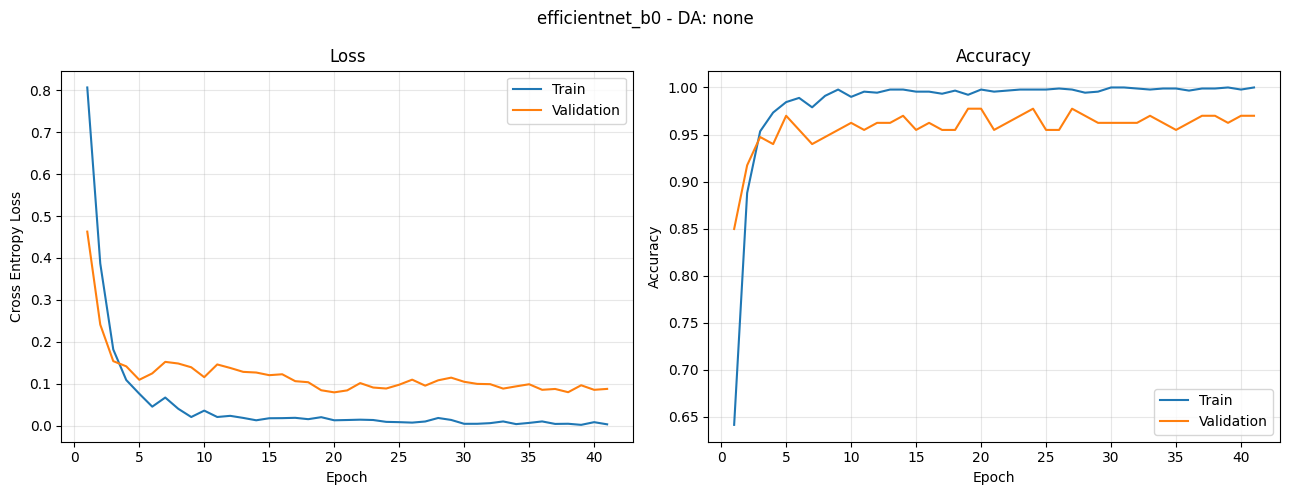

Gráficos salvos em: /content/drive/MyDrive/SIN393_Bean_Leaf_Classification/history/efficientnet_b0_none_curves.png


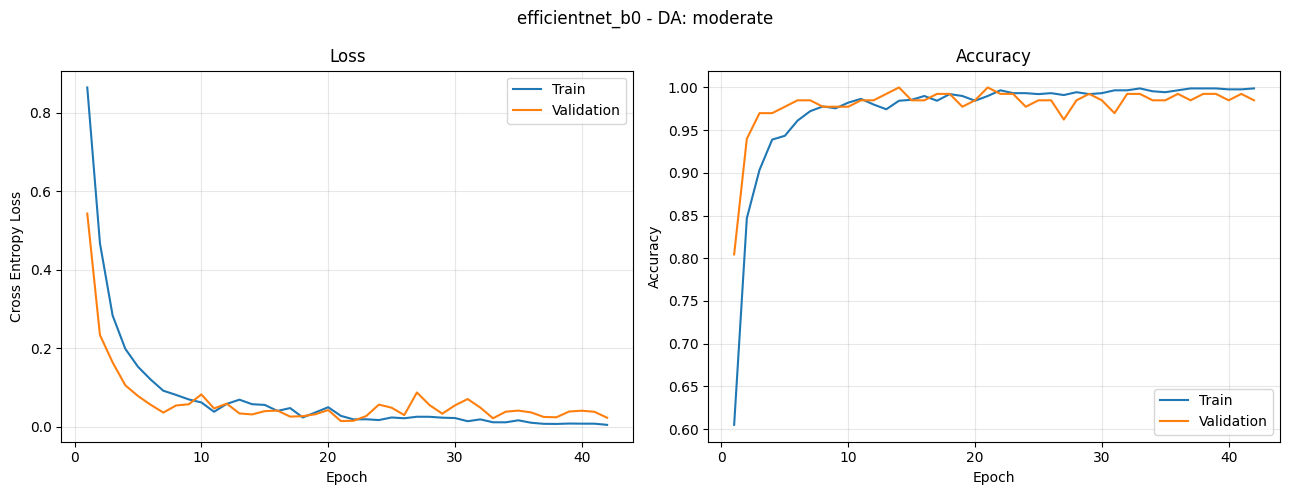

Gráficos salvos em: /content/drive/MyDrive/SIN393_Bean_Leaf_Classification/history/efficientnet_b0_moderate_curves.png


In [ ]:
for model_name in model_list_:
    for da_train in da_list_:
        history = pd.read_csv(
            os.path.join(HISTORY_DIR, f"{model_name}_{da_train}.csv")
        )
        plot_training_history(history, model_name, da_train)

## 6.3 Matrizes de confusão da validação

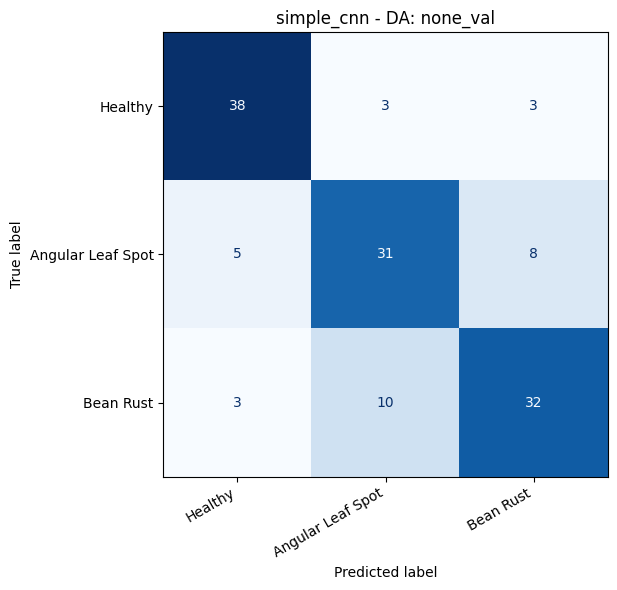

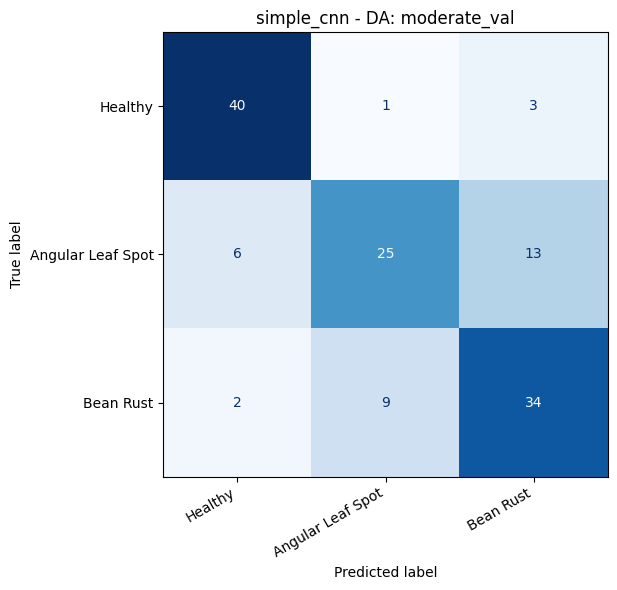

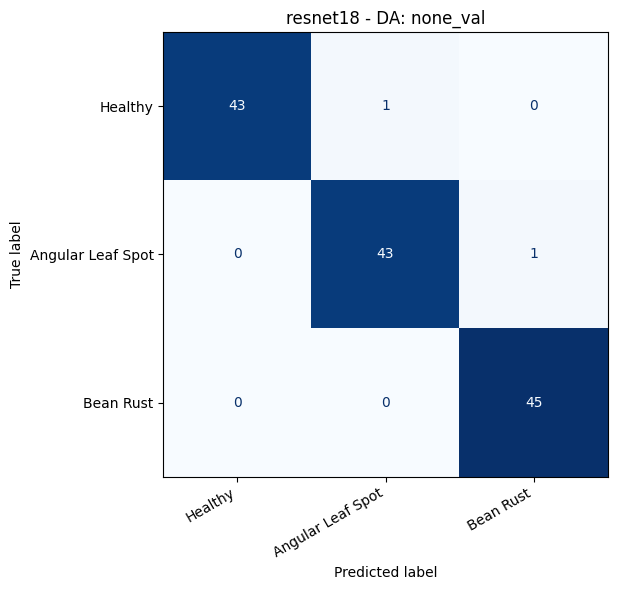

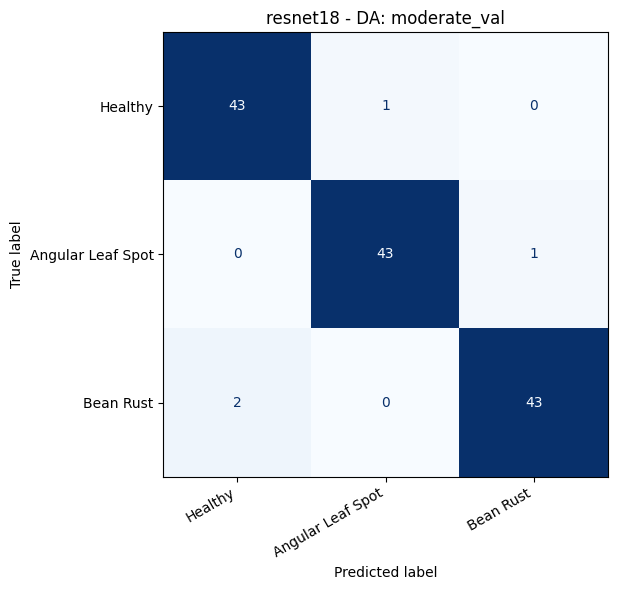

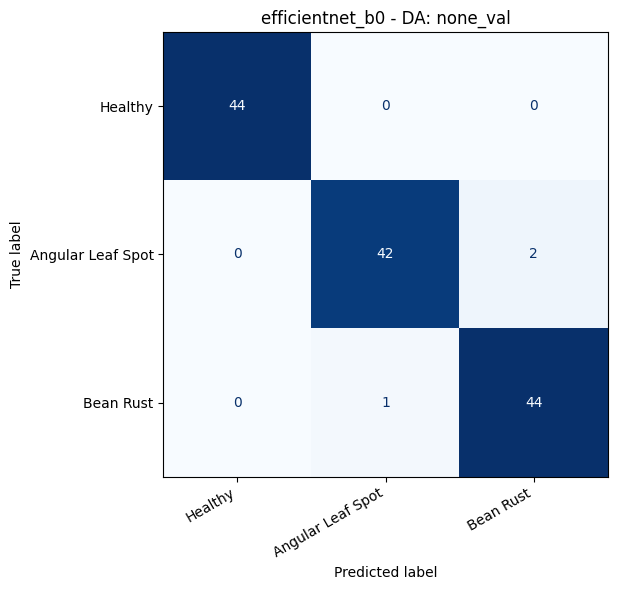

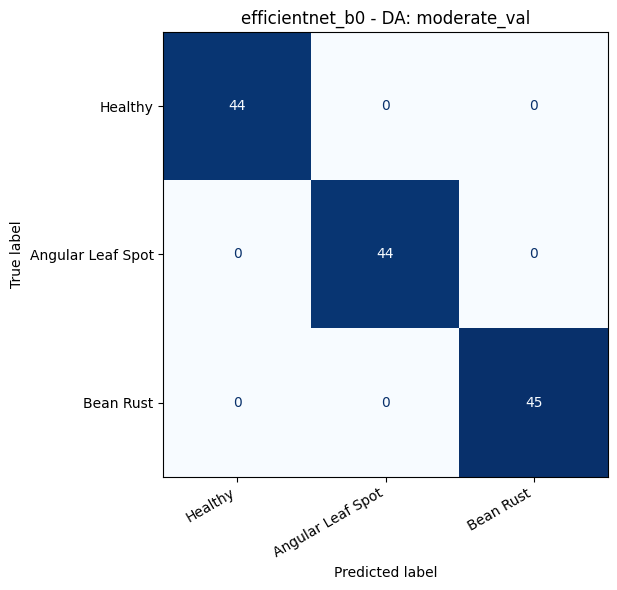

In [ ]:
for model_name in model_list_:
    for da_train in da_list_:
        evaluation_name = f"{da_train}_val"
        cm = load_confusion_matrix(model_name, evaluation_name)
        plot_confusion_matrix(cm, model_name, evaluation_name)

## 6.4 Matrizes de confusão do teste

In [ ]:
for model_name in model_list_:
    for da_train in da_list_:
        evaluation_name = f"{da_train}_test"
        cm = load_confusion_matrix(model_name, evaluation_name)
        plot_confusion_matrix(cm, model_name, evaluation_name)

## 6.5 Resumo final

Resultados de teste registrados no artigo:

| Modelo | DA | Época | Acurácia | Precisão | Recall | F1-score |
|---|---|--:|--:|--:|--:|--:|
| CNN simples | Sem DA | 41 | 0,7744 | 0,7749 | 0,7753 | 0,7743 |
| CNN simples | Moderado | 56 | 0,7444 | 0,7432 | 0,7453 | 0,7417 |
| ResNet-18 | Sem DA | 47 | 0,9474 | 0,9515 | 0,9481 | 0,9466 |
| ResNet-18 | Moderado | 28 | 0,9549 | 0,9561 | 0,9554 | 0,9547 |
| EfficientNet-B0 | Sem DA | 20 | 0,9398 | 0,9425 | 0,9404 | 0,9395 |
| **EfficientNet-B0** | **Moderado** | **21** | **0,9774** | **0,9779** | **0,9776** | **0,9775** |

A célula abaixo gera o resumo da execução atual.

In [ ]:
summary = pd.read_csv(os.path.join(RESULTS_DIR, "summary_val_test.csv"))
best = summary.iloc[0]
print(f"\nMelhor modelo pela validação: {best['model']} | DA: {best['da']}")
print(f"Teste -> Acurácia: {best['test_accuracy']:.4f} | F1: {best['test_f1']:.4f}")

display(summary.round(4))

# 7. Interpretabilidade (Grad-CAM)

Regiões que mais influenciaram as predições nas imagens que a EfficientNet-B0 com DA errou no teste.

## 7.1 Seleção dos modelos e das imagens

In [ ]:
# Modelos e imagens usados no Grad-CAM
model_cnn, _ = load_best_model("simple_cnn", "none", args, device)
model_res, _ = load_best_model("resnet18", "moderate", args, device)
model_eff, _ = load_best_model("efficientnet_b0", "moderate", args, device)

_, _, test_loader = get_dataloaders(
    "efficientnet_b0", args.height, args.width, args.batch_size
)
_, _, _, y_true, y_pred = evaluate_model(model_eff, test_loader, device)

# Até três imagens de teste classificadas incorretamente pela EfficientNet-B0
erros_eff = [
    (arquivo, real, previsto)
    for arquivo, real, previsto in zip(test_df["image:FILE"], y_true, y_pred)
    if real != previsto
][:3]

## 7.2 Funções do Grad-CAM

In [ ]:
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

CLASSES = ["Sadia", "Mancha angular", "Ferrugem"]
SIGLAS  = ["S", "MA", "F"]
rotulo_real = dict(zip(test_df["image:FILE"], test_df["category"]))
plt.rcParams.update({"font.family": "serif", "font.size": 7})

def gerar_cam(model, camada, model_name, arq):
    """Devolve (imagem com mapa sobreposto, classe prevista, confiança)."""
    tf = get_transforms(model_name, args.height, args.width, "none")
    with Image.open(os.path.join(path, arq)) as img:
        img = img.convert("RGB")
    x = tf(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0]
    classe = int(probs.argmax())

    with GradCAM(model=model, target_layers=[camada]) as cam:
        mapa = cam(input_tensor=x, targets=None)[0]

    rgb = np.asarray(img.resize((args.width, args.height)), dtype=np.float32) / 255
    return show_cam_on_image(rgb, mapa, use_rgb=True), classe, float(probs[classe])

def figura_grad_cam_coluna(modelos, arquivos, nome_arquivo, largura=3.45):
    n_lin, n_col = len(modelos) + 1, len(arquivos)
    lado = (largura - 0.35) / n_col                     # tamanho de cada imagem (polegadas)
    fig, axs = plt.subplots(n_lin, n_col, figsize=(largura, lado * n_lin + 0.75),
                            squeeze=False, layout="constrained")
    fig.get_layout_engine().set(w_pad=0.01, h_pad=0.01, wspace=0.02, hspace=0.02)

    for j, arq in enumerate(arquivos):
        real = int(rotulo_real[arq])

        # Linha 0: imagem original, com a classe real
        with Image.open(os.path.join(path, arq)) as img:
            axs[0, j].imshow(img.convert("RGB").resize((args.width, args.height)))
        axs[0, j].set_title(f"({chr(97 + j)}) {CLASSES[real]}",
                            fontsize=7, fontweight="bold", pad=2)

        # Demais linhas: Grad-CAM de cada modelo
        for i, (nome, model, camada, mname) in enumerate(modelos, start=1):
            sobreposta, prev, conf = gerar_cam(model, camada, mname, arq)
            axs[i, j].imshow(sobreposta)
            marca = "acerto" if prev == real else "erro"
            axs[i, j].set_title(f"{SIGLAS[prev]} {conf:.0%} ({marca})", fontsize=6.5, pad=2)

    for ax in axs.flat:
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)

    axs[0, 0].set_ylabel("Original", fontsize=7, fontweight="bold")
    for i, (nome, *_) in enumerate(modelos, start=1):
        axs[i, 0].set_ylabel(nome, fontsize=7, fontweight="bold")

    # Barra de cores horizontal, embaixo
    cbar = fig.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap="jet"),
                        ax=axs[-1, :].tolist(), location="bottom",
                        shrink=0.6, aspect=30, pad=0.02)
    cbar.set_ticks([0, 1], labels=["baixa", "alta"])
    cbar.set_label("Relevância (Grad-CAM)", fontsize=6.5, labelpad=1)
    cbar.ax.tick_params(labelsize=6.5, length=2, pad=1)

    base = os.path.join(METRICS_DIR, nome_arquivo)
    fig.savefig(base + ".pdf", bbox_inches="tight", pad_inches=0.01)
    fig.savefig(base + ".png", dpi=300, bbox_inches="tight", pad_inches=0.01)
    plt.show()

## 7.3 Mapas Grad-CAM

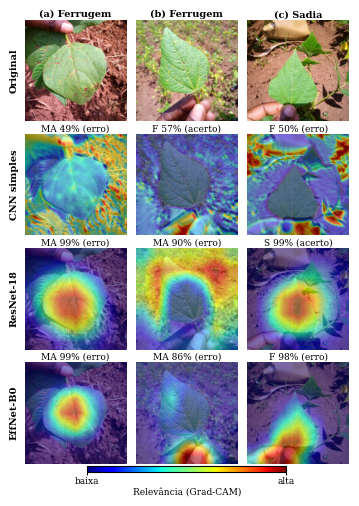

In [ ]:
modelos = [
    ("CNN simples", model_cnn, model_cnn.conv2,        "simple_cnn"),
    ("ResNet-18",   model_res, model_res.layer4[-1],   "resnet18"),
    ("EffNet-B0",   model_eff, model_eff.features[-1], "efficientnet_b0"),
]
figura_grad_cam_coluna(modelos, [e[0] for e in erros_eff], "gradcam_coluna")